# Main notebook for Optics to MRI registration

In [1]:
# Import libraries and functions
from module.utils import *
from module.utils_BRATS import *
from module.main_functions import *


id_patient = 0

# Indicate the path where MR volumes and optical images are located
Patient_ID_array = np.array(["P_025"])
print("Patient",Patient_ID_array[id_patient])


Mypath = Paths("/home/caredda/Videos/Optical_MRI_data/" + Patient_ID_array[id_patient], RGB_optics=True)


# #####################
# # Path and filenames
# #####################
# main_path = "/home/caredda/Videos/Optical_MRI_data/" + Patient_ID_array[id_patient]

# # main_path_optics = main_path + "/optics_HSI/"  #HSI
# main_path_optics = main_path + "/optics/" # RGB



# Load parameters
params = Params()



params_file = Mypath.main_path+"/Params.json"
if os.path.exists(params_file):
    print("Param file exists")
    params = Params.load(params_file)
else:
    print("Param file does not exist")



Patient P_025
Param file exists


# Extract brain surface

TODO: split brain extraction and surface extraction

In [ ]:
error = main_extract_brain(Mypath, params)
print(error)

error = main_get_surface_mask(Mypath, params)
print(error)

error, proj = main_plot_extracted_brain(Mypath)

plt.figure()
plt.imshow(proj)


# Get tumor segmentation in T1 space

In [ ]:
error = main_get_tumor_segmentation(Mypath)
print(error)


# [Debug] Test preprocess BRATS segmentation

In [ ]:
main_path = Mypath.main_path
output_dir = Mypath.output_dir


main_path_MRI = main_path + "/MRI/"

filename_t1 = main_path_MRI+"T1.nii"
filename_flair = main_path_MRI+"FLAIR.nii"
filename_t1_bet = output_dir+"r_T1_bet.nii.gz"


#Preprocess data in BRATS space
param_transform_atlas = preprocess_exam_in_brats_style_ITK(filename_t1, filename_flair, filename_t1_bet, output_dir)




#Free GPU cache
torch.cuda.empty_cache()


#Process tumor segmentation
segmenter = AdultGliomaSegmenter()
segmenter.infer_single(
    t1c = output_dir+"r_T1_bet_atlas.nii.gz",
    t1n = output_dir+"r_T1_bet_atlas.nii.gz",
    t2f = output_dir+"r_FLAIR_bet_atlas.nii.gz",
    t2w = output_dir+"r_FLAIR_bet_atlas.nii.gz",
    output_file=output_dir+"segmentation_atlas_space.nii.gz",
    log_file = output_dir+"log.txt"
)


# Registration back to T1 space")
filename_tumor = output_dir+ "segmentation_atlas_space.nii.gz"

register_tumor_segmentation_to_T1_space(output_dir, filename_t1_bet, filename_tumor, param_transform_atlas)

# Register fMRI on T1

A rigid transform is used because fMRI are usually cropped. If an affine transform is used, the registered volume does not fit the brain.

In [ ]:

# params.register_fMRI_to_T1 = True
error = main_register_fMRI_to_T1(Mypath, params)
print(error)


error, slice_T1, slice_fMRI = main_plot_fMRI_T1_registration(Mypath)
print(error)


# Plot overlay of registered slices
plt.figure(figsize=(6,6))
plt.imshow(slice_T1)  # Base image
plt.imshow(slice_fMRI, cmap="hot", alpha=0.5)  # Overlay with transparency
plt.axis("off")
plt.title("Overlay of Registered MRI Slices")
plt.show()





# Rotation of the MRI volume and projection with an angle

1) Load the MRI volumes
2) Calculate the center of gravitiy of the tumor segmenation
3) Calculate a new orthonormal basis. Consider that the vector between the center of mass of the tumor and the origin of MRI is the z axis
4) Calculate rotation matrix between origin basis and the new orthonormal basis
5) Create an affine transform
6) Use the resampling filter to apply the transform
7) Process the projections

Spacing projection [0.46875, 0.46875]
Success
Success


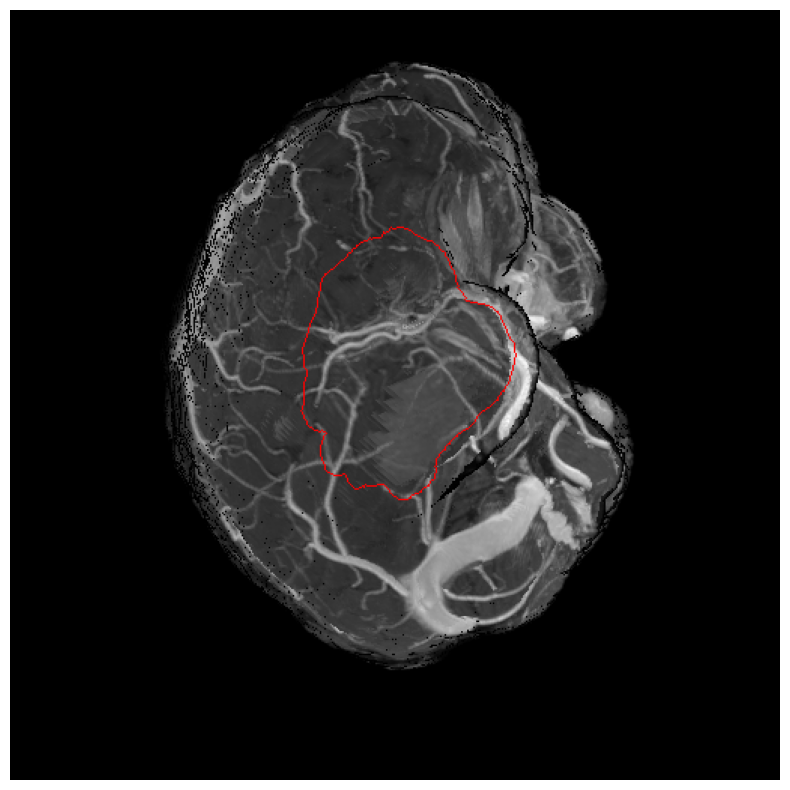

In [2]:
#Get MRI projection
# params.projection_type = "Transverse"
# params.projection_type = "Sagital"
# params.projection_type = "Coronal"
error = main_get_MRI_projection(Mypath, params)
print(error)


#Plot projection
error, proj = main_plot_MRI_Projection(Mypath)
print(error)

plt.figure(figsize=(10,10))
plt.imshow(proj)
plt.axis('off')
plt.show()


# Contrast enhancement and blood vessel segmentation

In [ ]:
#get skeleton vessel in MRI projection
error = main_get_vessels_in_MRI(Mypath, params)
print(error)

#get skeleton vessel in Optical image
error = main_get_vessels_in_optics(Mypath, params)
print(error)

#plot
error,display = main_plot_vessel_skeletons(Mypath)

plt.figure()
plt.imshow(display)
plt.show()
print(error)


# [Debug] place optics on MRI

In [ ]:
output_dir = Mypath.output_dir
main_path_optics = Mypath.main_path_optics

#Set filenames
filename_MRI = output_dir+"T1_proj_skeleton.nii.gz"
filename_mask_MRI = output_dir+"Mask_Proj_MRI.nii.gz"
filename_tumor = output_dir+"Mask_Proj_Tumor.nii.gz"


#Check if image is RGB or HSI
filename_initial_img = main_path_optics+"initial_img.png"
_,suffix_out_optics = is_RGB_optical_image(filename_initial_img)
filename_optics = output_dir+"optics_skeleton"+suffix_out_optics+".nii.gz"
filename_mask_otpics = output_dir+"optics_mask"+suffix_out_optics+".nii.gz"

#Load optics image resolution
res_opt_in_mm = float(np.loadtxt(main_path_optics+"resolution.txt"))


#Load files
MRI_proj = itk.imread(filename_MRI,itk.UC)
mask_MRI = itk.imread(filename_mask_MRI,itk.UC)
mask_tumor = itk.imread(filename_tumor,itk.UC)

Optics_img = itk.imread(filename_optics,itk.UC)
Optical_mask=  itk.imread(filename_mask_otpics,itk.UC)


#Get center of mass of tumor and optical mask
kp_Optics, kp_Optics_phys, _kpts_MRI_tumor, _kpts_MRI_tumor_phys = get_alignment_points(Optical_mask, Optics_img, MRI_proj, mask_tumor,
                                                                                        params.kpts_MRI_tumor, params.kpt_optics, params.touch_vessel)

kpts_MRI_tumor = _kpts_MRI_tumor
kpts_MRI_tumor_phys = _kpts_MRI_tumor_phys


id_kp_MRI = 0
kp_MRI_phys = kpts_MRI_tumor_phys[id_kp_MRI]
kp_MRI = kpts_MRI_tumor[id_kp_MRI]


#Change origin of optics slice to match keypoint
change_origin(filenames_MRI= [filename_MRI],
            filenames_optics= [filename_optics],
            kpt_Optics= kp_Optics_phys,
            kpt_MRI= kp_MRI_phys)


#Load volumes with origin changed
filename_MRI = filename_MRI.split('.')[0]+"_origin_changed.nii.gz"
filename_optics = filename_optics.split('.')[0]+"_origin_changed.nii.gz"
    

#Show registration for the minimal metric
open_itksnap_with_overlay(filename_MRI, filename_optics)

# Optics to MRI Registration. 

The center of rotation is located on MRI projection at the center of mass of the tumor projection.
In the optical image, the center of rotation is located at the center of mass of the optical mask

In [ ]:
#Process registration
# error = main_Optics_to_MRI_registration(Mypath, params)
# print(error)


#Plot registration results
error, display_img =  plot_registration_results(Mypath, params)
print(error)

plt.figure()
plt.title("MRI (red) and registered optical skeletons (blue)")
plt.imshow(cv.cvtColor(display_img,cv.COLOR_BGR2RGB))
plt.show()



# Plot registration metric

95


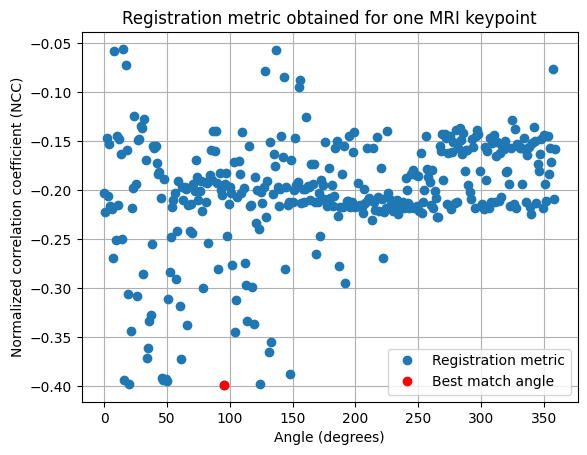

-0.39879


In [23]:
output_dir = Mypath.output_dir
main_path_optics = Mypath.main_path_optics


if params.multi_metric_multi_images:
    result_dir = output_dir+"Rotation_mutli_metric_image"
else:
    result_dir = output_dir+"Rotation"

#Load initial optical image
filename_initial_img_optics = main_path_optics+"initial_img.png"

if os.path.exists(filename_initial_img_optics):
    #Check if optical imaging is RGB or HSI
    _,suffix_out_optics = is_RGB_optical_image(filename_initial_img_optics)

    #save and display metric
    output_metric = np.loadtxt(result_dir +"/metrics"+suffix_out_optics+".txt")

    #Get best match
    angle, id_kp_MRI = get_id_kp_MRI_angle(result_dir +"/metrics"+suffix_out_optics+".txt")
    print(angle)
    plt.figure()
    plt.plot(np.arange(0,360),output_metric.T, 'o', label='Registration metric')
    plt.plot(angle,output_metric[angle], 'ro', label='Best match angle')
    plt.xlabel("Angle (degrees)")
    plt.ylabel("Normalized correlation coefficient (NCC)")
    plt.title("Registration metric obtained for one MRI keypoint")
    plt.legend(loc="best")
    plt.grid()
    plt.show()
    
    print(output_metric[angle])

# Project Optics image/stats on T1 [Create projection]
Problem: décallage en rotation quand use_upscaled_images = False 

In [ ]:
#Project optical image/stats on MRI projection
error = main_project_optical_image_on_MRI(Mypath, params)
print(error)

#plot results
error,display2 = main_plot_Optical_image_projected_on_MRI(Mypath)
print(error)



plt.figure(figsize=(10,10))
plt.imshow(cv.cvtColor(display2,cv.COLOR_BGR2RGB))
plt.show()



#Project optical image/stats on MRI projection
#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")


# # fMRI_filenames=[dir_fMRI+"r_RS_SCA_inferenceL_motor_rotated_Mask_proj.png",
# #                 dir_fMRI+"r_RS_SCA_inferenceR_motor_rotated_Mask_proj.png"]
# # fOptics_filenames = [dir_foptics+"RGB_inferenceL_reg_motor_mask.png",
# #                      dir_foptics+"RGB_inferenceR_reg_motor_mask.png"]

# # fMRI_filenames=[dir_fMRI+"r_RS_SCA_inferenceL_sensory_rotated_Mask_proj.png",
# #                 dir_fMRI+"r_RS_SCA_inferenceR_sensory_rotated_Mask_proj.png"]
# # fOptics_filenames = [dir_foptics+"RGB_inferenceL_reg_sensory_mask.png",
# #                      dir_foptics+"RGB_inferenceR_reg_sensory_mask.png"]


_fMRI_filenames = [Mypath.main_path+"/MRI/fMRI/inferences/"+"zone_MGfwe.nii"]        #r_zone_MGfwe_Mask_proj.png
_fOptics_filenames = [Mypath.main_path+"/optics/foptics_"+suffix_out_optics+"/"+"Z_stats_Hb.txt"]  #dir_foptics+"Z_stats_Hb_mask.png"
 




colors_fOptics = [(255,0,0),(0,0,255)]
colors_fMRI = [(255,255,0),(0,215,255)]

error, display = main_plot_fOptics_fMRI_stats_projected_on_MRI(Mypath,
                                                 _fMRI_filenames=_fMRI_filenames,
                                                 _fOptics_filenames=_fOptics_filenames,
                                                 colors_fMRI=colors_fMRI,
                                                 colors_fOptics=colors_fOptics)


print(error)
plt.figure(figsize=(20,20))
plt.imshow(cv.cvtColor(display,cv.COLOR_BGR2RGB))
plt.show()



# Create Optics volume registered in T1 space

In [ ]:
#Create optical volume in T1 space
error = main_reconstruct_Optics_volume(Mypath)
print(error)

#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")
open_MRIcroGL_with_overlay(Mypath.output_dir+"r_T1_bet.nii.gz", Mypath.output_dir + "Projection/Rec_Optical_T1"+suffix_out_optics+".nii.gz")


# [Debug] Test refine projection (by taking into account the brain curvature)

In [ ]:
main_path_optics = Mypath.main_path_optics
output_dir = Mypath.output_dir

#Check if optical imaging is RGB or HSI
filename_optics = main_path_optics+"initial_img.png"
if not os.path.exists(filename_optics):
    print("Optical image not found at")

_,suffix_out_optics = is_RGB_optical_image(filename_optics)

#Load optical volumes
B_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_B"+suffix_out_optics+".nii.gz", itk.F)
G_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_G"+suffix_out_optics+".nii.gz", itk.F)
R_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_R"+suffix_out_optics+".nii.gz", itk.F)


filename_MRI_surface = output_dir+'surface_mask_rotated.nii.gz'
filename_tumor = output_dir+'Tumor_rotated.nii.gz'

surface = itk.imread(filename_MRI_surface, itk.F)
tumor = itk.imread(filename_tumor, itk.F)

# Get numpy arrays
np_B_vol = itk.GetArrayFromImage(B_vol)
np_G_vol = itk.GetArrayFromImage(G_vol)
np_R_vol = itk.GetArrayFromImage(R_vol)

np_surface = itk.GetArrayFromImage(surface)
np_tumor = itk.GetArrayFromImage(tumor)


# Calculate projection
np_B_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_B_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)

np_G_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_G_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)

np_R_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_R_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)


BGR_proj = np.zeros((np_B_vol_projection.shape[0], np_B_vol_projection.shape[1], 3), dtype=np.uint8)
BGR_proj[:, :, 0] = np_B_vol_projection.astype(np.uint8)
BGR_proj[:, :, 1] = np_G_vol_projection.astype(np.uint8)
BGR_proj[:, :, 2] = np_R_vol_projection.astype(np.uint8)

plt.figure(figsize=(10,10))
plt.imshow(cv.cvtColor(BGR_proj,cv.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Optical image projection in T1 space")
plt.show()









# [TEMP FOR ADITHEP] Create MRI seed image
1) Create mask
2) Run project optics image/stats on T1
3) Run Create Optics volume

In [ ]:

#seed image
filename_optics = Mypath.main_path_optics+"initial_img.png"
in_img = cv.imread(filename_optics)

#Seed image
pos = (200,379)
seed = np.zeros((in_img.shape[0],in_img.shape[1]),dtype=np.uint8)
seed[pos[0]-10:10+pos[0],pos[1]-10:10+pos[1]] = 255

np.savetxt(Mypath.main_path_optics+"foptics/RGB_seed_sensory.txt",seed)


# Project MRI on optical image

Success


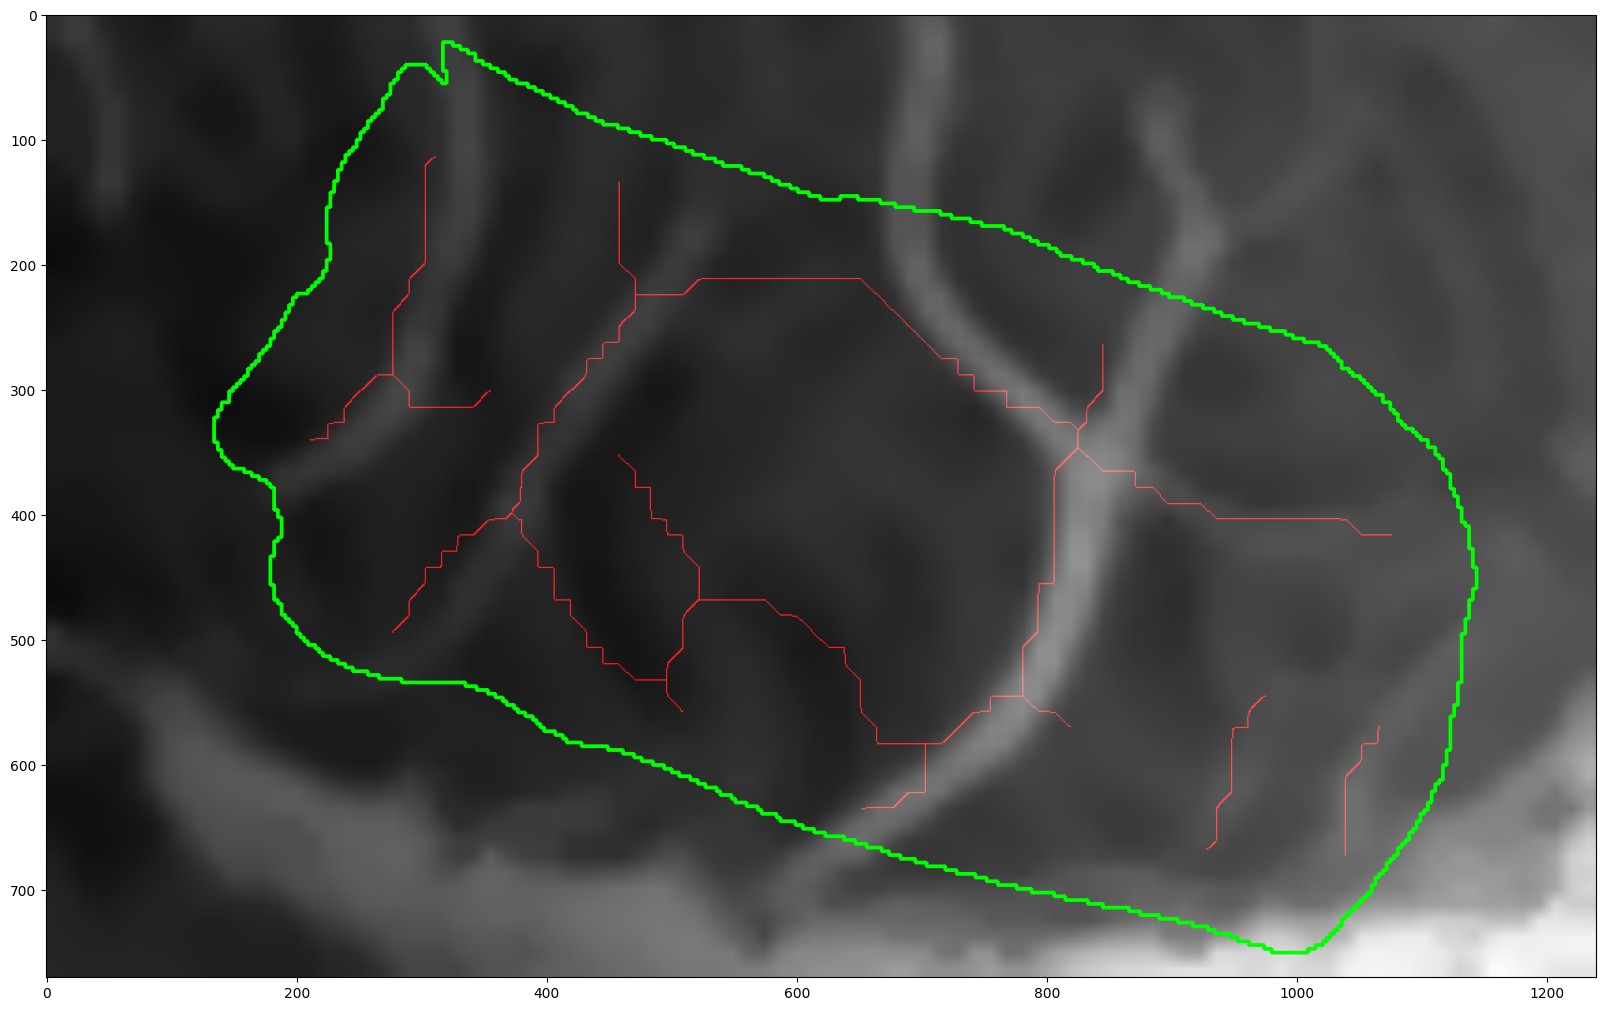

['/home/caredda/Videos/Optical_MRI_data/P_025/optics/foptics/Z_stats_Hb.txt']


In [ ]:
#Project MRI on optics space
error = main_project_MRI_in_optics_space(Mypath, params)
print(error)

#Plot results
error,display = main_plot_MRI_projected_on_Optics_space(Mypath)
print(error)

plt.figure(figsize=(20,20))
plt.imshow(display)
plt.show()




#Project optical image/stats on MRI projection
#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")
dir_fMRI = Mypath.output_dir + "Projection/fMRI/"
dir_foptics = Mypath.output_dir + "Projection/foptics_"+suffix_out_optics+"/"


fMRI_filenames = [Mypath.main_path+"/MRI/fMRI/inferences/"+"zone_MGfwe.nii"]        #r_zone_MGfwe_Mask_proj.png
fOptics_filenames = [Mypath.main_path_optics+"foptics/"+"Z_stats_Hb.txt"]  #dir_foptics+"Z_stats_Hb_mask.png"
print(fOptics_filenames)

colors_fOptics = [(255,0,0),(0,0,255)]
colors_fMRI = [(255,255,0),(0,215,255)]

error, display = main_plot_fOptics_fMRI_stats_projected_on_optics(Mypath,
                                                 _fMRI_filenames=fMRI_filenames,
                                                 _fOptics_filenames=fOptics_filenames,
                                                 colors_fMRI=colors_fMRI,
                                                 colors_fOptics=colors_fOptics)

if error == "Success":
    plt.figure(figsize=(20,20))
    plt.imshow(cv.cvtColor(display,cv.COLOR_BGR2RGB))
    plt.show()

# Registration validation

In [ ]:
output_dir = Mypath.output_dir

print("Patient ID",Patient_ID_array[id_patient])

#Load images
mri = cv.imread(output_dir+"MRI_proj_enhanced.png",cv.IMREAD_ANYCOLOR)
optics = cv.imread(output_dir+"RGB_registered_on_MRI.png")

#Load landmarks
points_optics = np.loadtxt(output_dir+"verification_landmarks/optics.txt")#.astype(int)
points_mri = np.loadtxt(output_dir+"verification_landmarks/mri.txt")#.astype(int)

#Get MRI resolution
filename_MRI_proj = output_dir+"Proj_MRI.nii.gz"
MRI_proj = itk.imread(filename_MRI_proj, itk.F)
reso = np.array(MRI_proj.GetSpacing())


print("MRI resolution: ",reso )


#Compute Euclidean distance in pixels
dist_mm = np.sqrt(((points_optics[:,0] - points_mri[:,0])*reso[0])**2 + ((points_optics[:,1] - points_mri[:,1])*reso[1])**2)
print("Euclidean distance",dist_mm.mean(),dist_mm.std())



plt.figure(figsize=(20,20))
plt.subplot(121)
plt.imshow(optics)
for i in range(points_optics.shape[0]):
    plt.plot(points_optics[i,0],points_optics[i,1],'ro')
plt.subplot(122)
plt.imshow(mri)
for i in range(points_mri.shape[0]):
    plt.plot(points_mri[i,0],points_mri[i,1],'ro')
plt.show()


plt.figure(figsize=(20,20))
plt.imshow(mri)
for i in range(points_mri.shape[0]):
    plt.plot(points_mri[i,0],points_mri[i,1],'bo')

for i in range(points_optics.shape[0]):
    plt.plot(points_optics[i,0],points_optics[i,1],'ro')
plt.show()

# Create mesh of T1 and registered optical file

In [ ]:

output_dir = Mypath.output_dir
main_path_optics = Mypath.main_path_optics


# Load the MRI data
nsub = 3
mesh_mri = process_mesh(output_dir+'r_T1_bet.nii.gz',nsub)
mesh_optical = process_mesh(output_dir +"Rec_Optical_T1.nii.gz",nsub)

save_path = "/home/caredda/temp/"

# Save the mesh to an STL file
mesh_mri.save(save_path+"MRI_mesh.stl")
mesh_optical.save(save_path+"Optics_mesh.stl")

#save texture for optics
input_img = cv.imread(main_path_optics+"initial_img.png")
mask = (cv.imread(main_path_optics+"mask.png",cv.IMREAD_GRAYSCALE)/255).astype(np.uint8)
for i in range(input_img.shape[2]):
    input_img[:,:,i] *= mask
cv.imwrite(save_path+"texture_optics.png",input_img)




# Mean ans std for validation landmarks

In [34]:
metric_m = np.array([1.75, 1.32, 1.22, 1.30, 2.25, 1.77, 0.85, 1.09, 2.69, 1.89, 1.68, 2.21, 1.65, 1.22, 1.08, 1.06, 1.56, 1.7, 2.13, 2.38, 1.62, 1.48, 2, 0.98,1.72])
metric_s = np.array([0.58, 1.27, 0.33, 0.22, 0.95, 0.48, 0.67, 0.99, 0.77, 1.08, 0.56, 1, 0.15, 0.46, 0.96, 0.22, 0.48, 1.72, 0.23, 0.49, 0.49, 0.63, 0.8])

reso = np.array([1.17, 1.27, 0.46, 0.46, 0.47, 0.46, 0.46, 0.5, 1, 0.46, 0.46, 0.46, 0.56, 0.9, 0.46, 0.46, 0.46, 0.46, 1.17, 0.46, 0.34, 0.44, 0.24, 0.44, 0.49])

print("MRI resolution", reso.mean(), reso.std())
print("Mean metric", metric_m.mean(),metric_m.std())
print("Std metric", metric_s.mean(), metric_s.std())

MRI resolution 0.5804 0.27300520141565066
Mean metric 1.6239999999999997 0.4660042918257298
Std metric 0.675217391304348 0.3740596274859582


# Plot all results in one big image

In [37]:
from module.utils import *

path = "/home/caredda/Videos/Optical_MRI_data/"

Patient_ID_array = np.array(["P_023", "P_025","P_028","P_031","P_032", "P_033", "P_035", "P_040","P_045","P_048","P_051","P_054","P_055","P_058","P_059","P_060","P_061","P_064","P_066","P_068","P_075","P_077","P_078","P_081","P_083"])  

print(Patient_ID_array.shape)

#Load first images
optics = cv.imread(path + Patient_ID_array[0] + "/results/Optical_img_projected_on_MRI2.png")


#resize
f = 10
new_shape = (int(f*optics.shape[1]),int(f*optics.shape[0]))
optics = cv.resize(optics, (int(f*optics.shape[1]),int(f*optics.shape[0])), interpolation= cv.INTER_LINEAR)

nb_row = 9
nb_col = 3
space = f*30
out = np.zeros(((new_shape[1]+space)*nb_row, (new_shape[0]+space)*nb_col + space*(nb_col-1),3),dtype = optics.dtype)

id = 0

for r in range(nb_row):
    for c in range(nb_col):
        if id>=25:
            break
        p = Patient_ID_array[id]
        id +=1

        #Load images
        optics = cv.imread(path + p + "/results/Optical_img_projected_on_MRI2.png")

        #resize image
        optics = cv.resize(optics, (new_shape[0],new_shape[1]), interpolation= cv.INTER_LINEAR)

        #Copy to output
        r_start = r*(new_shape[1]+space)+space
        r_stop = r_start+new_shape[1]
        c_start = c*(new_shape[0]+space)
        c_stop = c_start + new_shape[0]
        out[r_start:r_stop,c_start:c_stop,:] = optics

cv.imwrite(path+"results.png",out)




(25,)


True